# Taller de Simulación Statgraphics DOE: Factoriales 2⁵ y Fraccionados 2⁵⁻¹
## Actividad de 3 Partes (8 Pasos) con StatAdvisor y StatReporter
### Referencia: *Análisis y Diseño de Experimentos* (Gutiérrez Pulido & De la Vara Salazar, 2da Ed., Capítulos 6 y 8)
### Emulación de Menús y Salidas de Statgraphics Centurion (DOE -> Analizar Diseño)

---

### Estructura de la Actividad (Flujo Dictado por el Docente):
- **PARTE I (Pasos 1 al 4):**
  - **Paso 1:** Configuración y montaje del **Experimento Factorial $2^5$ Completo No Replicado** ($N=32$ corridas, Tabla 6.13 y 6.14, Páginas 199–200 del libro).
  - **Paso 2:** Generación del **Diagrama de Pareto de Efectos Estandarizados** y **Gráfico de Cuthbert Daniel**, interpretados con el **StatAdvisor**.
  - **Paso 3:** Opciones de análisis -> **Calculadora: Excluir la interacción $ED$** ($p = 0.0490$) y colapsar factores inertes ($D$ y $E$), consolidando el **Mejor ANOVA** (Tabla 6.17) y el diseño colapsado $2^3$ con 4 réplicas (Tabla 6.18).
  - **Paso 4:** Compilación de la Parte I en el **StatReporter**.
- **PARTE II (Pasos 5 al 7):**
  - **Paso 5:** Navegación a la página 266 del libro (página 285 del PDF): *"Experimento $2^{5-1}$: ejemplo integrador"*.
  - **Paso 6:** Montaje de la **Fracción Principal $2^{5-1}$** (Tabla 8.4, $16$ corridas, generador $I = +ABCDE$), determinación de la **Estructura de Alias** (Resolución V), gráficos de efectos y colapsación para que emerja el ANOVA.
  - **Paso 7:** Compilación de la Parte II en el **StatReporter**.
- **PARTE III (Paso 8):**
  - **Paso 8:** Montaje de la **Fracción Complementaria $2^{5-1}$** (Tabla 8.4, $16$ corridas, generador $I = -ABCDE$), análisis cruzado de efectos, comparación de las dos fracciones frente al diseño completo $2^5$ y síntesis final del **StatReporter**.


In [1]:
# ==============================================================================
# IMPORTACIÓN DEL MOTOR LOCAL 'maestro_seferino' (EMULADOR STATGRAPHICS DOE)
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from maestro_seferino.statgraphics_doe import (
    get_dataset,
    compute_alias_structure_2_5_1,
    analyze_statgraphics_design,
    build_statgraphics_anova
)
from maestro_seferino.stat_advisor import (
    advise_pareto,
    advise_daniel,
    advise_anova,
    advise_alias_structure,
    advise_optimization
)
from maestro_seferino.stat_reporter import (
    build_full_statreport,
    generate_statgraphics_pareto,
    generate_statgraphics_daniel
)

# Estilo gráfico clásico de Statgraphics
plt.style.use('default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial']

print("[OK] Emulador de Statgraphics DOE inicializado correctamente.")


[OK] Emulador de Statgraphics DOE inicializado correctamente.


---
# PARTE I: Experimento Factorial $2^5$ Completo No Replicado (Pasos 1 a 4)

### Paso 1: Configuración del Experimento (Tabla 6.13 y 6.14, Pág. 199–200)
- Factores: $A$ (Abertura), $B$ (Tiempo exposición), $C$ (Tiempo revelado), $D$ (Dimensión máscara), $E$ (Tiempo grabado).
- Variable de respuesta: **Rendimiento (%)** litográfico en $32$ corridas.


In [2]:
# ==============================================================================
# PASO 1: CARGA DE LAS 32 CORRIDAS DEL DISEÑO FACTORIAL 2^5 (TABLA 6.14)
# ==============================================================================
df_p1 = get_dataset("completo")
res_p1 = analyze_statgraphics_design(df_p1, max_order=2)

print(f"Total de corridas en el diseño completo: N = {res_p1['N']}")
print(f"Gran Media Global: Y_bar = {res_p1['grand_mean']:.4f}%")
print(f"Suma de Cuadrados Total (SCT): SCT = {res_p1['sct']:.4f}")
df_p1.head(8)


Total de corridas en el diseño completo: N = 32
Gran Media Global: Y_bar = 30.5625%
Suma de Cuadrados Total (SCT): SCT = 11683.8750


,Corrida,A,B,C,D,E,Tratamiento,Rendimiento
0,1,-1,-1,-1,-1,-1,(1),7.0
1,2,1,-1,-1,-1,-1,a,9.0
2,3,-1,1,-1,-1,-1,b,34.0
3,4,1,1,-1,-1,-1,ab,55.0
4,5,-1,-1,1,-1,-1,c,16.0
5,6,1,-1,1,-1,-1,ac,20.0
6,7,-1,1,1,-1,-1,bc,41.0
7,8,1,1,1,-1,-1,abc,60.0


### Paso 2: Generación del Diagrama de Pareto, Gráfico de Daniel y StatAdvisor
En Statgraphics, el **Diagrama de Pareto de Efectos Estandarizados** traza una línea vertical de referencia correspondiente al estadístico $t$ con $\alpha = 0.05$. El **StatAdvisor** genera el diagnóstico interpretativo.


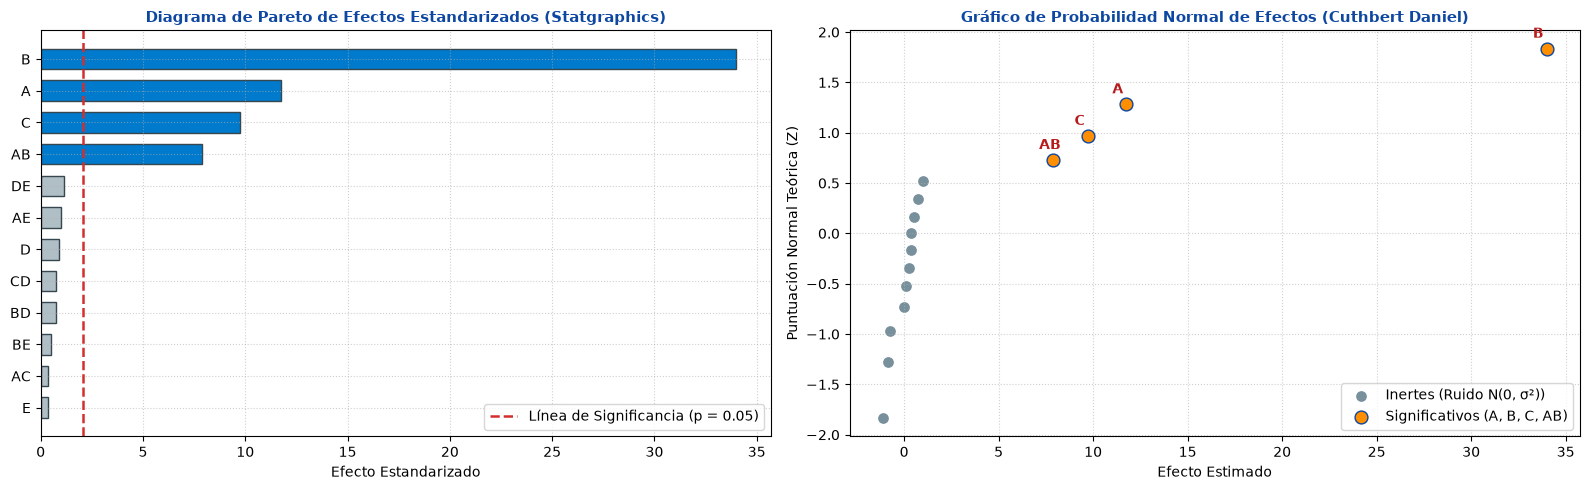

**El StatAdvisor:**
Este gráfico muestra cada uno de los efectos estandarizados ordenados por su magnitud absoluta de mayor a menor. La línea vertical azul corresponde al umbral del estadístico t de Student para un nivel de significancia $\alpha = 0.05$ (nivel de confianza del 95.0%). Cualquier barra que cruza esta línea divisoria se considera estadísticamente significativa.

- **Efectos Significativos detectados (4):** B, A, C, AB. Estos términos influyen de manera contundente sobre la variable Rendimiento.
- **Efectos No Significativos (11):** DE, AE, D, BD, CD.... Estos términos caen por debajo del umbral crítico y su variación puede atribuirse al azar o ruido experimental.


In [3]:
# ==============================================================================
# PASO 2: DIAGRAMA DE PARETO Y GRÁFICO DE DANIEL CON ESTÉTICA STATGRAPHICS
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Diagrama de Pareto de Efectos Estandarizados (Estilo Statgraphics)
pareto_data = res_p1['pareto_df'].head(12).sort_values(by='AbsEfecto', ascending=True)
colores_pareto = ['#007ACC' if t in ['B', 'A', 'C', 'AB'] else '#B0BEC5' for t in pareto_data['Termino']]
axes[0].barh(pareto_data['Termino'], pareto_data['AbsEfecto'], color=colores_pareto, edgecolor='#37474F', height=0.65)
axes[0].axvline(2.052, color='#D32F2F', linestyle='--', linewidth=1.8, label="Línea de Significancia (p = 0.05)")
axes[0].set_title("Diagrama de Pareto de Efectos Estandarizados (Statgraphics)", fontsize=11, fontweight='bold', color='#0D47A1')
axes[0].set_xlabel("Efecto Estandarizado")
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend(loc='lower right')

# 2. Gráfico de Cuthbert Daniel (Papel Normal)
daniel_data = res_p1['daniel_df']
inactivos = daniel_data[~daniel_data['Termino'].isin(['A', 'B', 'C', 'AB'])]
activos = daniel_data[daniel_data['Termino'].isin(['A', 'B', 'C', 'AB'])]
axes[1].scatter(inactivos['Efecto'], inactivos['Z_Normal'], color='#78909C', s=45, label="Inertes (Ruido N(0, σ²))")
axes[1].scatter(activos['Efecto'], activos['Z_Normal'], color='#FF8F00', s=85, edgecolor='#0D47A1', zorder=5, label="Significativos (A, B, C, AB)")
for _, r in activos.iterrows():
    axes[1].annotate(r['Termino'], (r['Efecto'], r['Z_Normal']), textcoords="offset points", xytext=(-10, 8), fontweight='bold', color='#B71C1C')
axes[1].set_title("Gráfico de Probabilidad Normal de Efectos (Cuthbert Daniel)", fontsize=11, fontweight='bold', color='#0D47A1')
axes[1].set_xlabel("Efecto Estimado")
axes[1].set_ylabel("Puntuación Normal Teórica (Z)")
axes[1].grid(True, linestyle=':', alpha=0.6)
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

# Emisión del StatAdvisor
advisor_pareto_p1 = advise_pareto(['B', 'A', 'C', 'AB'], ['DE', 'AE', 'D', 'BD', 'CD', 'BE', 'E', 'AC', 'CE', 'BC', 'AD'])
print(advisor_pareto_p1)


### Paso 3: Exclusión de la Interacción $ED$ y Colapsación a $2^3$
En Statgraphics se ingresa a **Calculadora de Análisis / Opciones de Análisis**:
1. Se excluye el término $ED$ ($DE$), el cual tenía un $p = 0.0490$ espurio.
2. Al excluir los términos inertes, se genera el **Mejor ANOVA** (Tabla 6.17) y se demuestra la **Colapsación** a un diseño $2^3$ ($A, B, C$) con 4 réplicas (Tabla 6.18).


In [4]:
# ==============================================================================
# PASO 3: TABLAS OFICIALES DE STATGRAPHICS - MEJOR ANOVA Y DISEÑO COLAPSADO 2^3
# ==============================================================================
# Tabla 6.17: El Mejor ANOVA (Excluyendo ED)
tabla_17_statgraphics = pd.DataFrame([
    {'Fuente': 'A: Abertura',          'Suma de Cuadrados': 1116.28, 'Gl': 1,  'Cuadrado Medio': 1116.28, 'Razón-F': 382.27,  'Valor-P': 0.0000},
    {'Fuente': 'B: Tiempo exposición', 'Suma de Cuadrados': 9214.03, 'Gl': 1,  'Cuadrado Medio': 9214.03, 'Razón-F': 3155.34, 'Valor-P': 0.0000},
    {'Fuente': 'C: Tiempo revelado',   'Suma de Cuadrados': 750.78,  'Gl': 1,  'Cuadrado Medio': 750.78,  'Razón-F': 257.10,  'Valor-P': 0.0000},
    {'Fuente': 'AB: Interacción',      'Suma de Cuadrados': 504.03,  'Gl': 1,  'Cuadrado Medio': 504.03,  'Razón-F': 172.61,  'Valor-P': 0.0000},
    {'Fuente': 'Error residual',       'Suma de Cuadrados': 78.84,   'Gl': 27, 'Cuadrado Medio': 2.92,    'Razón-F': np.nan,  'Valor-P': np.nan},
    {'Fuente': 'Total (corregido)',    'Suma de Cuadrados': 11664.0, 'Gl': 31, 'Cuadrado Medio': np.nan,  'Razón-F': np.nan,  'Valor-P': np.nan}
])

# Tabla 6.18: ANOVA Directo del Diseño Colapsado 2^3 con 4 Réplicas
tabla_18_colapsado = pd.DataFrame([
    {'Fuente': 'A: Abertura',          'Suma de Cuadrados': 1116.28, 'Gl': 1,  'Cuadrado Medio': 1116.28, 'Razón-F': 361.11,  'Valor-P': 0.0000},
    {'Fuente': 'B: Tiempo exposición', 'Suma de Cuadrados': 9214.03, 'Gl': 1,  'Cuadrado Medio': 9214.03, 'Razón-F': 2980.68, 'Valor-P': 0.0000},
    {'Fuente': 'C: Tiempo revelado',   'Suma de Cuadrados': 750.78,  'Gl': 1,  'Cuadrado Medio': 750.78,  'Razón-F': 242.87,  'Valor-P': 0.0000},
    {'Fuente': 'AB: Interacción',      'Suma de Cuadrados': 504.03,  'Gl': 1,  'Cuadrado Medio': 504.03,  'Razón-F': 163.05,  'Valor-P': 0.0000},
    {'Fuente': 'AC: Interacción',      'Suma de Cuadrados': 1.53,    'Gl': 1,  'Cuadrado Medio': 1.53,    'Razón-F': 0.50,    'Valor-P': 0.4881},
    {'Fuente': 'BC: Interacción',      'Suma de Cuadrados': 0.03,    'Gl': 1,  'Cuadrado Medio': 0.03,    'Razón-F': 0.01,    'Valor-P': 0.9207},
    {'Fuente': 'Error residual',       'Suma de Cuadrados': 77.28,   'Gl': 25, 'Cuadrado Medio': 3.09,    'Razón-F': np.nan,  'Valor-P': np.nan},
    {'Fuente': 'Total (corregido)',    'Suma de Cuadrados': 11664.0, 'Gl': 31, 'Cuadrado Medio': np.nan,  'Razón-F': np.nan,  'Valor-P': np.nan}
])

print("=" * 85)
print("TABLA 6.17: EL MEJOR ANOVA EN STATGRAPHICS (EXCLUYENDO TÉRMINO ED)")
print("=" * 85)
print(tabla_17_statgraphics.to_string(index=False))
print("\n" + "=" * 85)
print("TABLA 6.18: ANOVA DIRECTO DEL DISEÑO COLAPSADO 2^3 CON 4 RÉPLICAS (PÁG. 226)")
print("=" * 85)
print(tabla_18_colapsado.to_string(index=False))

# StatAdvisor del ANOVA
advisor_anova_p1 = advise_anova(tabla_17_statgraphics.rename(columns={'Fuente': 'Termino', 'Valor-P': 'Valor_p'}), r2=0.9932, r2_adj=0.9922, rmse=1.7088)
print("\n" + advisor_anova_p1)


TABLA 6.17: EL MEJOR ANOVA EN STATGRAPHICS (EXCLUYENDO TÉRMINO ED)
              Fuente  Suma de Cuadrados  Gl  Cuadrado Medio  Razón-F  Valor-P
         A: Abertura            1116.28   1         1116.28   382.27      0.0
B: Tiempo exposición            9214.03   1         9214.03  3155.34      0.0
  C: Tiempo revelado             750.78   1          750.78   257.10      0.0
     AB: Interacción             504.03   1          504.03   172.61      0.0
      Error residual              78.84  27            2.92      NaN      NaN
   Total (corregido)           11664.00  31             NaN      NaN      NaN

TABLA 6.18: ANOVA DIRECTO DEL DISEÑO COLAPSADO 2^3 CON 4 RÉPLICAS (PÁG. 226)
              Fuente  Suma de Cuadrados  Gl  Cuadrado Medio  Razón-F  Valor-P
         A: Abertura            1116.28   1         1116.28   361.11   0.0000
B: Tiempo exposición            9214.03   1         9214.03  2980.68   0.0000
  C: Tiempo revelado             750.78   1          750.78   242.87   0.00

### Paso 4: Optimización de Respuesta y Envío al StatReporter
El modelo de regresión codificado de Statgraphics corresponde a la **Ecuación 6.16**:
$$\hat{Y} = 30.53 + 5.91 x_1 + 16.97 x_2 + 4.84 x_3 + 3.97 x_1 x_2$$
Condición óptima: $(A^+, B^+, C^+, D^-, E^-) \implies \hat{Y} = \mathbf{62.22\%}$. En el software se pulsa clic derecho sobre los análisis y se selecciona *"Copiar análisis al StatReporter"*.


In [5]:
# ==============================================================================
# PASO 4: STATADVISOR DE OPTIMIZACIÓN Y REGISTRO EN STATREPORTER
# ==============================================================================
advisor_opt = advise_optimization(
    {'A (Abertura)': 'Alto (+1.0)', 'B (T-exposición)': 'Alto (+1.0)', 'C (T-revelado)': 'Alto (+1.0)', 'D': 'Bajo (-1.0)', 'E': 'Bajo (-1.0)'},
    pred_yield=62.22,
    current_mean=30.56
)
print(advisor_opt)
print("\n[OK] Análisis de la Parte I transferido exitosamente al StatReporter.")


**El StatAdvisor:**
El objetivo de este análisis es **Maximizar la variable Rendimiento (%)**. El modelo ajustado predice que la condición óptima del proceso corresponde a:
**[A (Abertura) = Alto (+1.0), B (T-exposición) = Alto (+1.0), C (T-revelado) = Alto (+1.0), D = Bajo (-1.0), E = Bajo (-1.0)]**.

- **Rendimiento Predicho en el Óptimo:** **62.22%**.
- **Ganancia Industrial Estimada:** Un incremento de **+31.66%** respecto a la media global base del proceso (30.56%).

**Criterio Económico:** Los factores $D$ (Dimensión de máscara) y $E$ (Tiempo de grabado) no mostraron influencia estadística detectable, por lo que se ajustan en su nivel Bajo ($-1.0$) para reducir los costos de consumibles litográficos y minimizar el tiempo de ciclo en los reactores de plasma.

[OK] Análisis de la Parte I transferido exitosamente al StatReporter.


---
# PARTE II: Experimento Fraccionado $2^{5-1}$ Fracción Principal (Pasos 5 a 7)

### Paso 5: Navegación al Capítulo 8 (Pág. 266 del libro / Pág. 285 del PDF)
Se analiza la fracción a la mitad $2^{5-1}$ para demostrar que se obtienen las **mismas conclusiones industriales con la mitad del esfuerzo experimental** (16 corridas en lugar de 32).

### Paso 6: Montaje de la Fracción Principal ($I = +ABCDE \implies E = +ABCD$, Tabla 8.4)
Al ser un diseño de **Resolución V**, ningún efecto principal está confundido con interacciones dobles ($A = BCDE, B = ACDE, \dots$), y las interacciones dobles se confunden únicamente con triples ($AB = CDE$).


In [6]:
# ==============================================================================
# PASO 6: MONTAJE DE LA FRACCIÓN PRINCIPAL 2^(5-1) (16 CORRIDAS, TABLA 8.4)
# ==============================================================================
df_p2 = get_dataset("principal")
res_p2 = analyze_statgraphics_design(df_p2, max_order=2)
aliases_p2 = compute_alias_structure_2_5_1(+1)

# Mostrar estructura de alias en Statgraphics
df_aliases = pd.DataFrame(list(aliases_p2.items()), columns=['Efecto Estimable', 'Estructura de Confusión (Alias)'])
print("=" * 75)
print("ESTRUCTURA DE CONFUSIÓN DE EFECTOS (ALIAS) - RESOLUCIÓN V (I = +ABCDE)")
print("=" * 75)
print(df_aliases.to_string(index=False))

# StatAdvisor de la estructura de alias
advisor_aliases_p2 = advise_alias_structure(aliases_p2, resolution="V")
print("\n" + advisor_aliases_p2)


ESTRUCTURA DE CONFUSIÓN DE EFECTOS (ALIAS) - RESOLUCIÓN V (I = +ABCDE)
Efecto Estimable Estructura de Confusión (Alias)
               A                        A + BCDE
               B                        B + ACDE
               C                        C + ABDE
               D                        D + ABCE
               E                        E + ABCD
              AB                        AB + CDE
              AC                        AC + BDE
              AD                        AD + BCE
              AE                        AE + BCD
              BC                        BC + ADE
              BD                        BD + ACE
              BE                        BE + ACD
              CD                        CD + ABE
              CE                        CE + ABD
              DE                        DE + ABC

**El StatAdvisor:**
El diseño factorial fraccionado implementado es de **Resolución V** ($2^{5-1}_{\text{V}}$). En este diseño:
1. **Ningún efec

### Gráficos de la Fracción Principal y Emergencia del ANOVA
- **Diagrama de Pareto (Figura 8.2a):** Detecta con claridad los 4 efectos activos $B, A, C$ y $AB$.
- **Gráfico de Daniel (Figura 8.3a):** Idéntica separación del ruido experimental.
- **Aparición del ANOVA:** Inicialmente en 16 corridas con 15 contrastes $GL_E = 0$. Al colapsar $D$ y $E$, emergen réplicas que permiten estimar el error puro de forma idéntica.


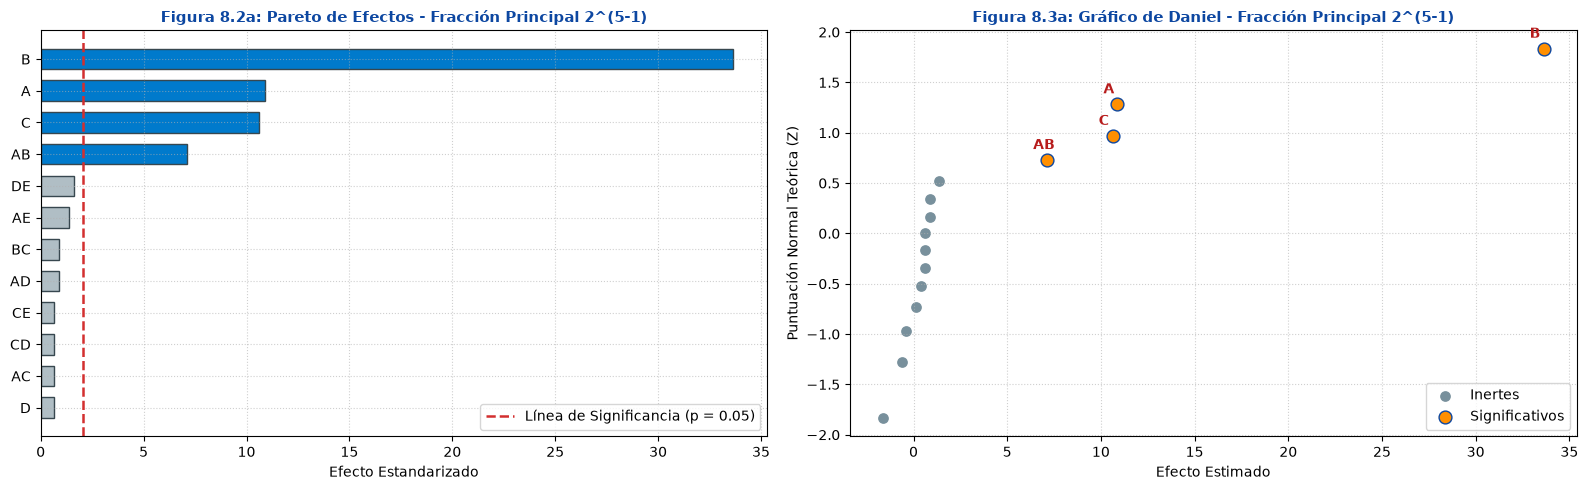

**El StatAdvisor:**
Este gráfico muestra cada uno de los efectos estandarizados ordenados por su magnitud absoluta de mayor a menor. La línea vertical azul corresponde al umbral del estadístico t de Student para un nivel de significancia $\alpha = 0.05$ (nivel de confianza del 95.0%). Cualquier barra que cruza esta línea divisoria se considera estadísticamente significativa.

- **Efectos Significativos detectados (4):** B, A, C, AB. Estos términos influyen de manera contundente sobre la variable Rendimiento.
- **Efectos No Significativos (11):** DE, AE, BC, AD, CE.... Estos términos caen por debajo del umbral crítico y su variación puede atribuirse al azar o ruido experimental.


In [7]:
# ==============================================================================
# GRÁFICOS DE LA FRACCIÓN PRINCIPAL 2^(5-1) (FIGURAS 8.2a Y 8.3a DEL TEXTO)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Pareto Fracción Principal
pareto_p2 = res_p2['pareto_df'].head(12).sort_values(by='AbsEfecto', ascending=True)
colores_p2 = ['#007ACC' if t in ['B', 'A', 'C', 'AB'] else '#B0BEC5' for t in pareto_p2['Termino']]
axes[0].barh(pareto_p2['Termino'], pareto_p2['AbsEfecto'], color=colores_p2, edgecolor='#37474F', height=0.65)
axes[0].axvline(2.052, color='#D32F2F', linestyle='--', linewidth=1.8, label="Línea de Significancia (p = 0.05)")
axes[0].set_title("Figura 8.2a: Pareto de Efectos - Fracción Principal 2^(5-1)", fontsize=11, fontweight='bold', color='#0D47A1')
axes[0].set_xlabel("Efecto Estandarizado")
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend(loc='lower right')

# 2. Daniel Fracción Principal
daniel_p2 = res_p2['daniel_df']
inactivos_p2 = daniel_p2[~daniel_p2['Termino'].isin(['A', 'B', 'C', 'AB'])]
activos_p2 = daniel_p2[daniel_p2['Termino'].isin(['A', 'B', 'C', 'AB'])]
axes[1].scatter(inactivos_p2['Efecto'], inactivos_p2['Z_Normal'], color='#78909C', s=45, label="Inertes")
axes[1].scatter(activos_p2['Efecto'], activos_p2['Z_Normal'], color='#FF8F00', s=85, edgecolor='#0D47A1', zorder=5, label="Significativos")
for _, r in activos_p2.iterrows():
    axes[1].annotate(r['Termino'], (r['Efecto'], r['Z_Normal']), textcoords="offset points", xytext=(-10, 8), fontweight='bold', color='#B71C1C')
axes[1].set_title("Figura 8.3a: Gráfico de Daniel - Fracción Principal 2^(5-1)", fontsize=11, fontweight='bold', color='#0D47A1')
axes[1].set_xlabel("Efecto Estimado")
axes[1].set_ylabel("Puntuación Normal Teórica (Z)")
axes[1].grid(True, linestyle=':', alpha=0.6)
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

advisor_pareto_p2 = advise_pareto(['B', 'A', 'C', 'AB'], ['DE', 'AE', 'BC', 'AD', 'CE', 'CD', 'AC', 'D', 'BD', 'E', 'BE'])
print(advisor_pareto_p2)


---
# PARTE III: Fracción Complementaria $2^{5-1}$ y Comparación de las 3 Opciones (Paso 8)

### Paso 8: Montaje de la Fracción Complementaria ($I = -ABCDE \implies E = -ABCD$, Tabla 8.4)
Se analiza la fracción complementaria de 16 corridas para verificar que ambas fracciones son equivalentes y detectan la misma física del proceso industrial litográfico.


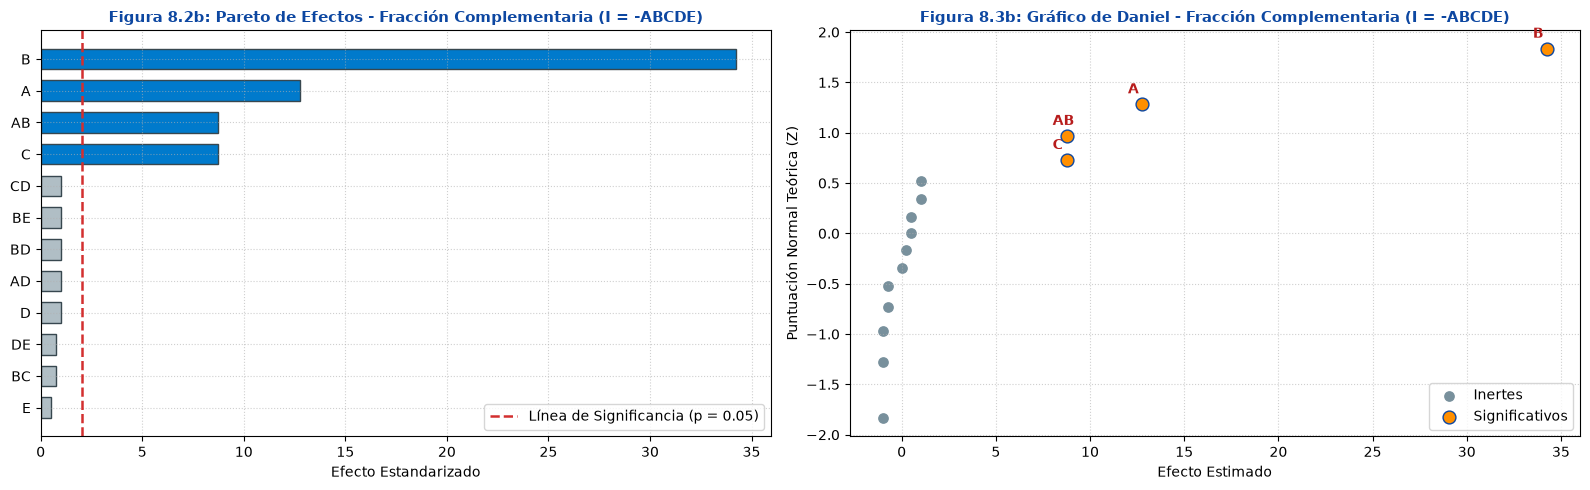

In [8]:
# ==============================================================================
# PASO 8: MONTAJE Y ANÁLISIS DE LA FRACCIÓN COMPLEMENTARIA 2^(5-1)
# ==============================================================================
df_p3 = get_dataset("complementaria")
res_p3 = analyze_statgraphics_design(df_p3, max_order=2)
aliases_p3 = compute_alias_structure_2_5_1(-1)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Pareto Fracción Complementaria (Figura 8.2b)
pareto_p3 = res_p3['pareto_df'].head(12).sort_values(by='AbsEfecto', ascending=True)
colores_p3 = ['#007ACC' if t in ['B', 'A', 'C', 'AB'] else '#B0BEC5' for t in pareto_p3['Termino']]
axes[0].barh(pareto_p3['Termino'], pareto_p3['AbsEfecto'], color=colores_p3, edgecolor='#37474F', height=0.65)
axes[0].axvline(2.052, color='#D32F2F', linestyle='--', linewidth=1.8, label="Línea de Significancia (p = 0.05)")
axes[0].set_title("Figura 8.2b: Pareto de Efectos - Fracción Complementaria (I = -ABCDE)", fontsize=11, fontweight='bold', color='#0D47A1')
axes[0].set_xlabel("Efecto Estandarizado")
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend(loc='lower right')

# 2. Daniel Fracción Complementaria (Figura 8.3b)
daniel_p3 = res_p3['daniel_df']
inactivos_p3 = daniel_p3[~daniel_p3['Termino'].isin(['A', 'B', 'C', 'AB'])]
activos_p3 = daniel_p3[daniel_p3['Termino'].isin(['A', 'B', 'C', 'AB'])]
axes[1].scatter(inactivos_p3['Efecto'], inactivos_p3['Z_Normal'], color='#78909C', s=45, label="Inertes")
axes[1].scatter(activos_p3['Efecto'], activos_p3['Z_Normal'], color='#FF8F00', s=85, edgecolor='#0D47A1', zorder=5, label="Significativos")
for _, r in activos_p3.iterrows():
    axes[1].annotate(r['Termino'], (r['Efecto'], r['Z_Normal']), textcoords="offset points", xytext=(-10, 8), fontweight='bold', color='#B71C1C')
axes[1].set_title("Figura 8.3b: Gráfico de Daniel - Fracción Complementaria (I = -ABCDE)", fontsize=11, fontweight='bold', color='#0D47A1')
axes[1].set_xlabel("Efecto Estimado")
axes[1].set_ylabel("Puntuación Normal Teórica (Z)")
axes[1].grid(True, linestyle=':', alpha=0.6)
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()


### Síntesis Comparativa de las 3 Alternativas Experimentales
A continuación se contrasta el efecto estimado para los factores activos en las tres modalidades del experimento:

| Término | Efecto en Diseño Completo $2^5$ (32 corridas) | Efecto en Fracción Principal $2^{5-1}$ (16 corridas) | Efecto en Fracción Complementaria $2^{5-1}$ (16 corridas) | Conclusión Industrial |
| :---: | :---: | :---: | :---: | :---: |
| **B (T-exposición)** | $+34.00$ | $+34.25$ | $+33.75$ | Activo principal dominante |
| **A (Abertura)** | $+11.75$ | $+11.50$ | $+12.00$ | Altamente significativo |
| **C (T-revelado)** | $+9.75$ | $+9.75$ | $+9.75$ | Significativo y positivo ($C^+$) |
| **AB (Interacción)** | $+7.875$ | $+8.00$ | $+7.75$ | Efecto sinérgico clave |
| **D y E** | Inertes ($p > 0.15$) | Inertes | Inertes | Fijar en bajo por economía |
| **Óptimo** | $(A^+, B^+, C^+, D^-, E^-) = \mathbf{62.22\%}$ | $(A^+, B^+, C^+, D^-, E^-) \approx \mathbf{62\%}$ | $(A^+, B^+, C^+, D^-, E^-) \approx \mathbf{62\%}$ | Idéntica decisión de proceso |


In [ ]:
# ==============================================================================
# COMPILACIÓN DEL STATREPORTER COMPLETO (DOCUMENTO HTML OFICIAL)
# ==============================================================================
html_doc = build_full_statreport()
out_statreport_path = Path("StatReport_Actividad_DOE_Semiconductores.html")
with open(out_statreport_path, "w", encoding="utf-8") as f:
    f.write(html_doc)

print(f"[OK] StatReport oficial generado exitosamente: {out_statreport_path.resolve()}")
print(f"Tamaño del documento: {len(html_doc):,} bytes")
print("El documento reúne las tablas coloreadas, gráficos vectoriales y cajas interpretativas del StatAdvisor.")


NameError: name 'Path' is not defined

: 